### Step 1 – Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

import warnings
warnings.filterwarnings("ignore")

### Step 2 – Load the Feature-Engineered Dataset

In [3]:
rfm = pd.read_csv("customer_feature_engineered.csv")

print("Dataset Shape:", rfm.shape)

rfm.head()

Dataset Shape: (93358, 19)


,customer_unique_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Customer_Segment,Average_Spending_Per_Order,Customer_Value_Category,Purchase_Intensity,Spending_Category,Customer_Value_Score,Loyalty_Category,Customer_Risk_Category,Customer_Engagement_Score,Purchase_Behaviour,Recency_Category
0,0000366f3b9a7992bf8c76cfdf3221e2,111,1,141.90,4,1,3,8,Loyal Customers,141.90,Medium Value,Low,Medium Value,141.90,Medium Loyalty,Low Risk,0.892857,Low Engagement Buyers,Moderate
1,0000b849f77a49e4a4ce2b2a4ca5be3f,114,1,27.19,3,1,1,5,At Risk,27.19,Low Value,Low,Low Value,27.19,Low Loyalty,High Risk,0.869565,Low Engagement Buyers,Moderate
2,0000f46a3911fa3c0805444483337064,536,1,86.22,1,1,2,4,At Risk,86.22,Low Value,Low,Low Value,86.22,Low Loyalty,High Risk,0.186220,Low Engagement Buyers,Inactive
3,0000f6ccb0745a6a4b88665a16c9f078,320,1,43.62,2,1,1,4,At Risk,43.62,Low Value,Low,Low Value,43.62,Low Loyalty,High Risk,0.311526,Low Engagement Buyers,Inactive
4,0004aac84e0df4da2b147fca70cf8255,287,1,196.89,2,1,4,7,Potential Customers,196.89,Medium Value,Low,Medium Value,196.89,Medium Loyalty,Medium Risk,0.347222,Low Engagement Buyers,Inactive


### Step 3 – Understand the Customer Data

In [4]:
print("Dataset Information:")
rfm.info()

print("\nRecency Statistics:")
print(rfm["Recency"].describe())

print("\nCustomer Segments:")
print(rfm["Customer_Segment"].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 93358 entries, 0 to 93357
Data columns (total 19 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   customer_unique_id          93358 non-null  object 
 1   Recency                     93358 non-null  int64  
 2   Frequency                   93358 non-null  int64  
 3   Monetary                    93358 non-null  float64
 4   R_Score                     93358 non-null  int64  
 5   F_Score                     93358 non-null  int64  
 6   M_Score                     93358 non-null  int64  
 7   RFM_Score                   93358 non-null  int64  
 8   Customer_Segment            93358 non-null  object 
 9   Average_Spending_Per_Order  93358 non-null  float64
 10  Customer_Value_Category     93358 non-null  object 
 11  Purchase_Intensity          93358 non-null  object 
 12  Spending_Category           93358 non-null  object 
 13  Customer_V

### Step 4 – Create the Churn Target

In [5]:
rfm["Churn"] = np.where(rfm["Recency"] > 180, 1, 0)

print("Churn Target Distribution:")
print(rfm["Churn"].value_counts())

print("\nChurn Percentage:")
print((rfm["Churn"].value_counts(normalize=True) * 100).round(2))

Churn Target Distribution:
Churn
1    55006
0    38352
Name: count, dtype: int64

Churn Percentage:
Churn
1    58.92
0    41.08
Name: proportion, dtype: float64


### Step 5 – Select Features for the Model

In [6]:
features = [
    "Frequency",
    "Monetary",
    "Average_Spending_Per_Order",
    "Purchase_Intensity",
    "Spending_Category",
    "Loyalty_Category"
]

X = rfm[features].copy()
y = rfm["Churn"]

print("Feature Dataset Shape:", X.shape)
print("\nTarget Dataset Shape:", y.shape)

print("\nSelected Features:")
print(X.head())

Feature Dataset Shape: (93358, 6)

Target Dataset Shape: (93358,)

Selected Features:
   Frequency  Monetary  Average_Spending_Per_Order Purchase_Intensity  \
0          1    141.90                      141.90                Low   
1          1     27.19                       27.19                Low   
2          1     86.22                       86.22                Low   
3          1     43.62                       43.62                Low   
4          1    196.89                      196.89                Low   

  Spending_Category Loyalty_Category  
0      Medium Value   Medium Loyalty  
1         Low Value      Low Loyalty  
2         Low Value      Low Loyalty  
3         Low Value      Low Loyalty  
4      Medium Value   Medium Loyalty  


### Step 6 – Encode Categorical Features

In [7]:
X = pd.get_dummies(
    X,
    columns=[
        "Purchase_Intensity",
        "Spending_Category",
        "Loyalty_Category"
    ],
    drop_first=True,
    dtype=int
)

print("Encoded Feature Shape:", X.shape)

print("\nEncoded Columns:")
print(X.columns.tolist())

X.head()

Encoded Feature Shape: (93358, 9)

Encoded Columns:
['Frequency', 'Monetary', 'Average_Spending_Per_Order', 'Purchase_Intensity_Low', 'Purchase_Intensity_Medium', 'Spending_Category_Low Value', 'Spending_Category_Medium Value', 'Loyalty_Category_Low Loyalty', 'Loyalty_Category_Medium Loyalty']


,Frequency,Monetary,Average_Spending_Per_Order,Purchase_Intensity_Low,Purchase_Intensity_Medium,Spending_Category_Low Value,Spending_Category_Medium Value,Loyalty_Category_Low Loyalty,Loyalty_Category_Medium Loyalty
0,1,141.90,141.90,1,0,0,1,0,1
1,1,27.19,27.19,1,0,1,0,1,0
2,1,86.22,86.22,1,0,1,0,1,0
3,1,43.62,43.62,1,0,1,0,1,0
4,1,196.89,196.89,1,0,0,1,0,1


### Step 7 – Split Data into Training and Testing Sets

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training Data Shape: (74686, 9)
Testing Data Shape: (18672, 9)

Training Target Distribution:
Churn
1    0.589
0    0.411
Name: proportion, dtype: float64

Testing Target Distribution:
Churn
1    0.589
0    0.411
Name: proportion, dtype: float64


### Step 8 – Train the Random Forest Model

In [9]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


### Step 9 – Make Churn Predictions

In [10]:
y_pred = rf_model.predict(X_test)

y_prob = rf_model.predict_proba(X_test)[:, 1]

print("Predictions Generated Successfully!")

print("\nFirst 10 Predictions:")
print(y_pred[:10])

print("\nFirst 10 Churn Probabilities:")
print(y_prob[:10].round(3))

Predictions Generated Successfully!

First 10 Predictions:
[0 1 0 0 1 1 1 1 1 1]

First 10 Churn Probabilities:
[0.133 1.    0.01  0.37  0.712 1.    0.644 1.    1.    0.97 ]


### Step 10 – Evaluate Model Accuracy

In [11]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 79.92 %


### Step 11 – Remove the Leakage Feature

In [12]:
X = rfm[[
    "Frequency",
    "Monetary",
    "Average_Spending_Per_Order",
    "Purchase_Intensity",
    "Spending_Category"
]].copy()

X = pd.get_dummies(
    X,
    columns=["Purchase_Intensity", "Spending_Category"],
    drop_first=True,
    dtype=int
)

print("Updated Feature Shape:", X.shape)
print("\nFeatures:")
print(X.columns.tolist())

Updated Feature Shape: (93358, 7)

Features:
['Frequency', 'Monetary', 'Average_Spending_Per_Order', 'Purchase_Intensity_Low', 'Purchase_Intensity_Medium', 'Spending_Category_Low Value', 'Spending_Category_Medium Value']


### Step 12 – Repeat Train-Test Split

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape: (74686, 7)
Testing Data Shape: (18672, 7)


### Step 13 – Train the Corrected Random Forest Model

In [14]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Corrected Random Forest Model Trained Successfully!")

Corrected Random Forest Model Trained Successfully!


### Step 14 – Generate Predictions Using the Corrected Model

In [15]:
y_pred = rf_model.predict(X_test)

y_prob = rf_model.predict_proba(X_test)[:, 1]

print("Predictions Generated Successfully!")

Predictions Generated Successfully!


### Step 15 – Evaluate the Corrected Model

In [16]:
accuracy = accuracy_score(y_test, y_pred)

print("Corrected Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Corrected Model Accuracy: 74.33 %

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.69      0.69      7671
           1       0.78      0.78      0.78     11001

    accuracy                           0.74     18672
   macro avg       0.73      0.74      0.74     18672
weighted avg       0.74      0.74      0.74     18672



### Step 16 – Generate the Confusion Matrix

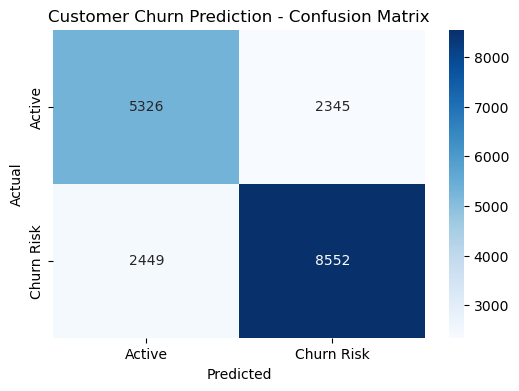

In [17]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Active", "Churn Risk"],
    yticklabels=["Active", "Churn Risk"]
)

plt.title("Customer Churn Prediction - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### Step 17 – Calculate ROC-AUC Score

In [18]:
roc_score = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", round(roc_score, 4))

ROC-AUC Score: 0.7925


### Step 18 – Visualize the ROC Curve

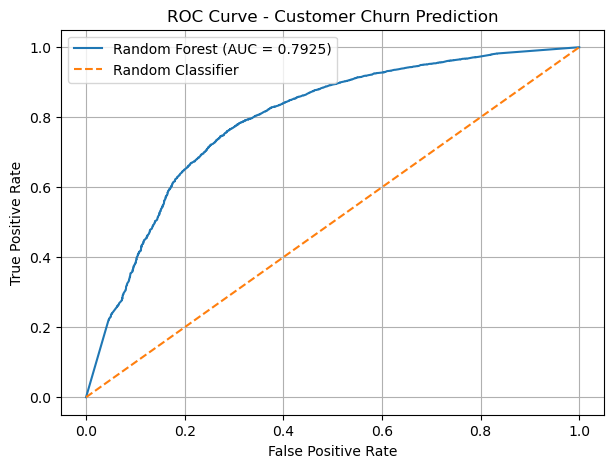

In [19]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label="Random Forest (AUC = 0.7925)")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.title("ROC Curve - Customer Churn Prediction")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.show()

### Step 19 – Identify Important Features

In [20]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

                          Feature  Importance
1                        Monetary    0.500391
2      Average_Spending_Per_Order    0.498282
0                       Frequency    0.000562
5     Spending_Category_Low Value    0.000231
6  Spending_Category_Medium Value    0.000208
4       Purchase_Intensity_Medium    0.000172
3          Purchase_Intensity_Low    0.000154


### Step 20 – Visualize Feature Importance

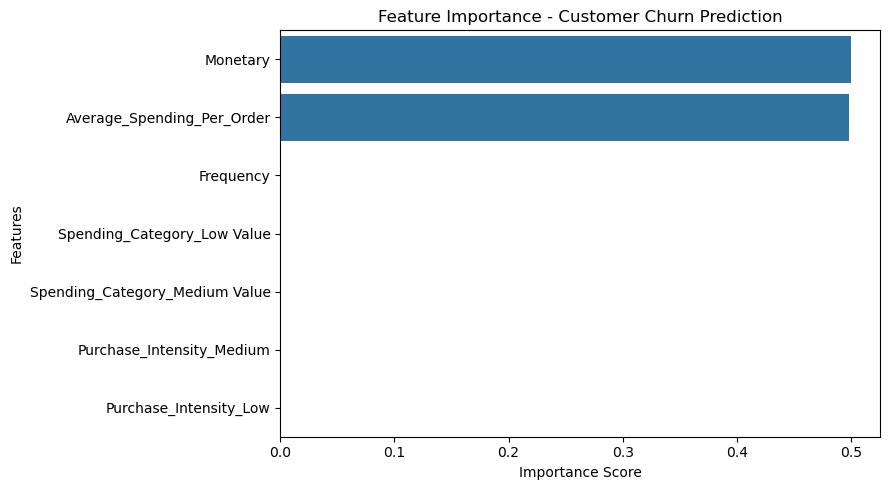

In [21]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Customer Churn Prediction")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

### Step 21 – Export Customer Churn Predictions

In [22]:
churn_results = rfm.loc[
    X_test.index, ["customer_unique_id"]
].copy()

churn_results["Actual_Churn"] = y_test
churn_results["Predicted_Churn"] = y_pred
churn_results["Churn_Probability"] = y_prob

churn_results.to_csv(
    "customer_churn_predictions.csv",
    index=False
)

print("Customer churn predictions exported successfully!")

churn_results.head()

Customer churn predictions exported successfully!


,customer_unique_id,Actual_Churn,Predicted_Churn,Churn_Probability
74597,cc4de577443a0710cf5fdfe9229a1411,0,0,0.275786
2259,06374ae87d5b7dd95b9528c9c6eda663,0,0,0.120000
78728,d78c02cd0949ff38724a310b0fc2abfe,1,0,0.010000
92978,fefa5385f7ccc46b5b43cd8b6914d44e,1,1,0.638425
59318,a28a5bf286affa0abc5f7dbc1ccb6a2d,1,1,0.889454


In [23]:
!pip install shap

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 751.9/751.9 kB 10.5 MB/s  0:00:00

   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------- 2/2 [shap]

